# Práctica OpenCV — Semana 8: tratamiento de imágenes

Este notebook calcula las métricas que solicita la guía. **Usa cinco fotografías propias del mismo objeto**
- `referencia.jpg`
- `oscura.jpg`
- `desenfocada.jpg`
- `fondo.jpg`
- `angulo.jpg`

In [7]:
import os, zipfile
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display

uploaded = files.upload()
REQUIRED = ['referencia.jpg', 'oscura.jpg', 'desenfocada.jpg', 'fondo.jpg', 'angulo.jpg']
missing = [name for name in REQUIRED if not os.path.exists(name)]
if missing:
    raise ValueError('Faltan archivos o los nombres no coinciden: ' + ', '.join(missing) + '. Renombra los archivos y vuelve a ejecutar la celda de carga.')
print('Archivos cargados correctamente.')

Saving angulo.jpg to angulo (1).jpg
Saving desenfocada.jpg to desenfocada (1).jpg
Saving fondo.jpg to fondo (1).jpg
Saving oscura.jpg to oscura (1).jpg
Saving referencia.jpg to referencia (1).jpg
Archivos cargados correctamente.


## 1. Visualizar y diagnosticar las cinco imágenes

- **Brillo**: promedio de intensidades en escala de grises; un valor bajo suele corresponder a una imagen más oscura.
- **Contraste**: desviación estándar de intensidades; sirve como aproximación sencilla.
- **Nitidez**: varianza del Laplaciano; normalmente una imagen desenfocada presenta un valor menor que su referencia, pero ruido y texturas también pueden elevarlo.
- **Resolución**: ancho × alto en píxeles.

No existe un umbral universal para decidir si una imagen es buena

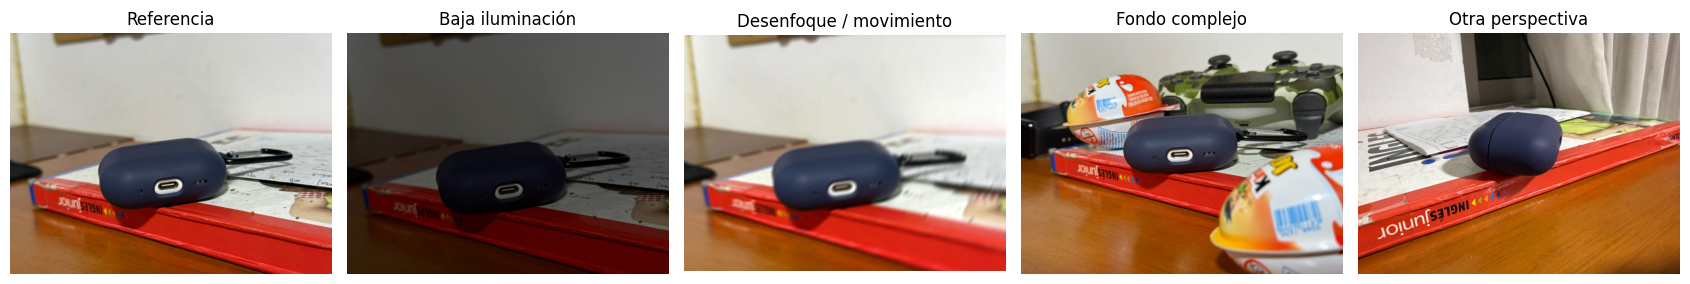

In [12]:
def load_image(path):
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError(f'OpenCV no pudo leer: {path}')
    return img

def metrics(path, img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    h, w = gray.shape
    return {
        'Archivo': path,
        'Ancho_px': int(w),
        'Alto_px': int(h),
        'Resolucion_px': f'{w} x {h}',
        'Canales': int(img.shape[2]) if img.ndim == 3 else 1,
        'Brillo_promedio': round(float(gray.mean()), 2),
        'Contraste_std': round(float(gray.std()), 2),
        'Nitidez_Laplaciano_var': round(float(cv2.Laplacian(gray, cv2.CV_64F).var()), 2),
        'Tamano_archivo_KB': round(os.path.getsize(path)/1024, 2)
    }

images = {name: load_image(name) for name in REQUIRED}
labels = {
 'referencia.jpg': 'Referencia',
 'oscura.jpg': 'Baja iluminación',
 'desenfocada.jpg': 'Desenfoque / movimiento',
 'fondo.jpg': 'Fondo complejo',
 'angulo.jpg': 'Otra perspectiva'
}

fig, axes = plt.subplots(1, 5, figsize=(17, 4))
for ax, name in zip(axes, REQUIRED):
    ax.imshow(cv2.cvtColor(images[name], cv2.COLOR_BGR2RGB))
    ax.set_title(labels[name])
    ax.axis('off')
plt.tight_layout()
plt.savefig('evidencia_cinco_imagenes.png', dpi=160, bbox_inches='tight')
plt.show()

## 2. Comparar JPG y PNG

Se utiliza la fotografía de referencia y se guarda en JPG con calidad 90 y en PNG, sin cambiar el tamaño en píxeles.

In [9]:
ref = images['referencia.jpg']
ok_jpg = cv2.imwrite('comparacion.jpg', ref, [cv2.IMWRITE_JPEG_QUALITY, 90])
ok_png = cv2.imwrite('comparacion.png', ref)
if not (ok_jpg and ok_png):
    raise RuntimeError('No se pudieron guardar las imágenes de comparación.')

format_rows = []
for name, fmt in [('comparacion.jpg', 'JPG (calidad 90)'), ('comparacion.png', 'PNG')]:
    im = load_image(name)
    h, w = im.shape[:2]
    format_rows.append({
        'Formato': fmt,
        'Resolucion_px': f'{w} x {h}',
        'Tamano_KB': round(os.path.getsize(name)/1024, 2)
    })
formats_df = pd.DataFrame(format_rows)
display(formats_df)
formats_df.to_csv('comparacion_formatos.csv', index=False, encoding='utf-8-sig')

,Formato,Resolucion_px,Tamano_KB
0,JPG (calidad 90),1600 x 1200,155.38
1,PNG,1600 x 1200,1356.16


## 3. Tratamiento de una imagen problemática

Se trabaja con `oscura.jpg` porque la condición propuesta es baja iluminación. Se usa el ejemplo de la guía: `alpha=1.2` y `beta=25`. El ajuste de brillo no corrige el desenfoque ni recupera información que no se capturó.

,Momento,Ancho_px,Alto_px,Brillo_promedio,Contraste_std,Nitidez_Laplaciano_var
0,Antes,1600,1200,53.15,29.57,4.46
1,Después,1600,1200,88.77,35.50,6.83


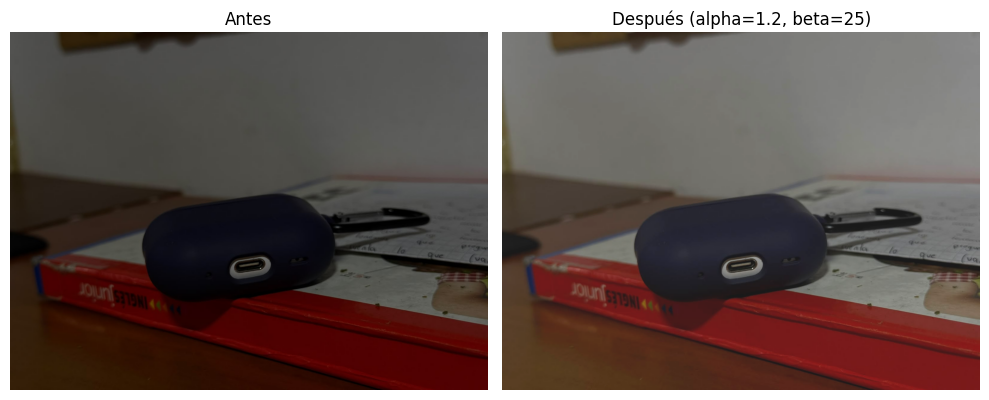

In [13]:
PROBLEM_IMAGE = 'oscura.jpg'
ALPHA = 1.2
BETA = 25
original = images[PROBLEM_IMAGE]
treated = cv2.convertScaleAbs(original, alpha=ALPHA, beta=BETA)
cv2.imwrite('tratada_oscura.jpg', treated, [cv2.IMWRITE_JPEG_QUALITY, 95])

before = metrics(PROBLEM_IMAGE, original)
after = metrics('tratada_oscura.jpg', treated)
compare_df = pd.DataFrame([
    {'Momento':'Antes', **{k: before[k] for k in ['Ancho_px','Alto_px','Brillo_promedio','Contraste_std','Nitidez_Laplaciano_var']}},
    {'Momento':'Después', **{k: after[k] for k in ['Ancho_px','Alto_px','Brillo_promedio','Contraste_std','Nitidez_Laplaciano_var']}}
])
display(compare_df)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB)); axes[0].set_title('Antes'); axes[0].axis('off')
axes[1].imshow(cv2.cvtColor(treated, cv2.COLOR_BGR2RGB)); axes[1].set_title(f'Después (alpha={ALPHA}, beta={BETA})'); axes[1].axis('off')
plt.tight_layout()
plt.savefig('evidencia_antes_despues.png', dpi=160, bbox_inches='tight')
plt.show()
